In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

In [3]:
with open("credit.csv") as file:
    df = pd.read_csv(file, sep=",")

In [4]:
cat_cols = ["Gender", "Student", "Married", "Ethnicity"]
for c in cat_cols:
    df[c] = df[c].astype("category")
df = pd.get_dummies(df, drop_first=True)

In [5]:
def evaluate_model(X, y, model):
    kf = KFold(n_splits=10, shuffle=True, random_state=42)
    scores = cross_val_score(model, X, y, cv=kf, scoring="accuracy")
    return scores


In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "KNN (k=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5))
    ]),
}

Income > 50, Logistic Regression accuracy: mean=0.9300 std=0.0444
Income > 50, Decision Tree accuracy: mean=0.8950 std=0.0568
Income > 50, Random Forest accuracy: mean=0.8775 std=0.0675
Income > 50, KNN (k=5) accuracy: mean=0.7500 std=0.0652


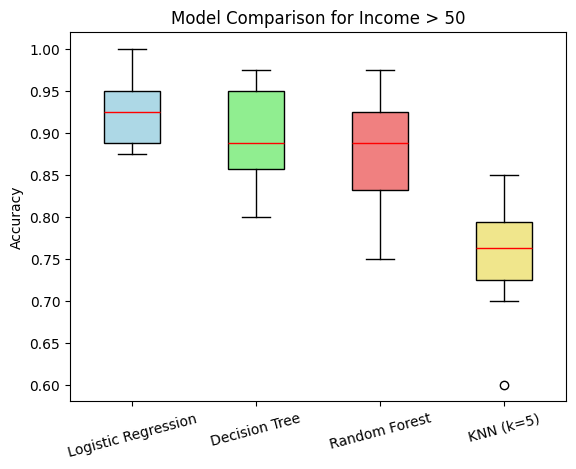

In [7]:
df_a = df.copy()
df_a["HighIncome"] = (df_a["Income"] > 50).astype(bool)
df_a = df_a.drop(columns=["Income"])
X_a = df_a.drop(columns=["HighIncome"])
y_a = df_a["HighIncome"]

scores_models = {}
for name, model in models.items():
    scores = evaluate_model(X_a, y_a, model)
    scores_models[name] = scores
    print(f"Income > 50, {name} accuracy: mean={scores.mean():.4f} std={scores.std():.4f}")

box_colors = ['lightblue', 'lightgreen', 'lightcoral', 'khaki']
boxplot = plt.boxplot(pd.DataFrame(scores_models), patch_artist=True,
                      medianprops=dict(color='red'))
for patch, color in zip(boxplot['boxes'], box_colors):
    patch.set_facecolor(color)
plt.title("Model Comparison for Income > 50")
plt.ylabel("Accuracy")
plt.xticks(range(1, len(scores_models) + 1), list(scores_models.keys()), rotation=15)
plt.show()

Number of credit cards, Logistic Regression accuracy: mean=0.2725 std=0.0810
Number of credit cards, Decision Tree accuracy: mean=0.2300 std=0.0545
Number of credit cards, Random Forest accuracy: mean=0.2800 std=0.0731
Number of credit cards, KNN (k=5) accuracy: mean=0.2375 std=0.0727


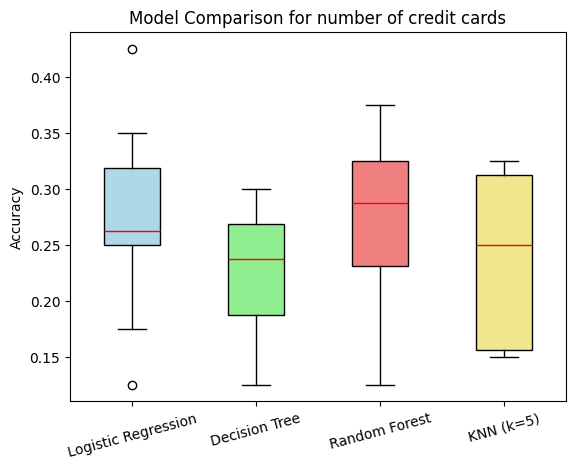

In [8]:
X_b = df.drop(columns=["Cards"])
y_b = df["Cards"]

scores_models = {}
for name, model in models.items():
    scores = evaluate_model(X_b, y_b, model)
    scores_models[name] = scores
    print(f"Number of credit cards, {name} accuracy: mean={scores.mean():.4f} std={scores.std():.4f}")

box_colors = ['lightblue', 'lightgreen', 'lightcoral', 'khaki']
boxplot = plt.boxplot(pd.DataFrame(scores_models), patch_artist=True,
                      medianprops=dict(color='red'))
for patch, color in zip(boxplot['boxes'], box_colors):
    patch.set_facecolor(color)
plt.title("Model Comparison for number of credit cards")
plt.ylabel("Accuracy")
plt.xticks(range(1, len(scores_models) + 1), list(scores_models.keys()), rotation=15)
plt.show()

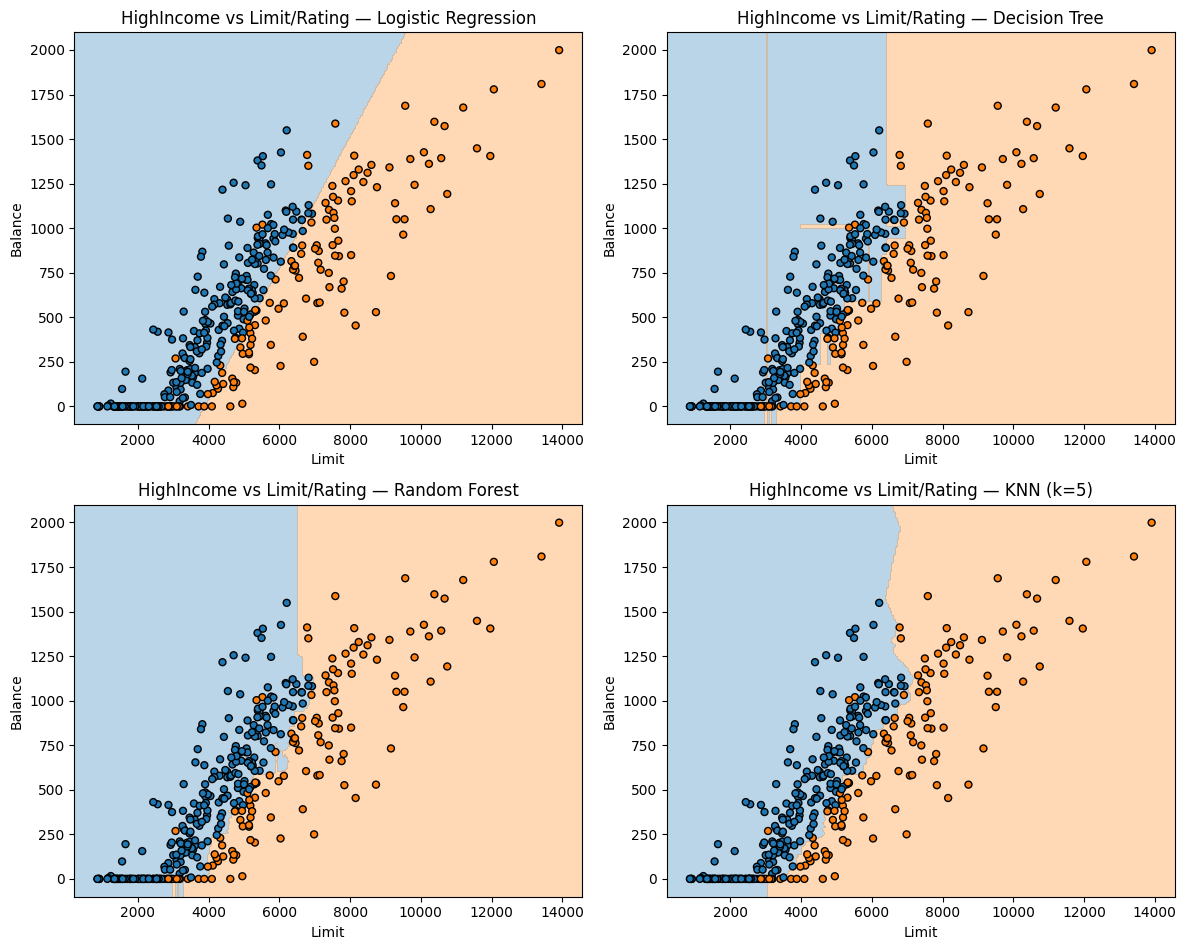

In [10]:
df_c = df.copy()
df_c["HighIncome"] = (df_c["Income"] > 50).astype(bool)
df_c = df_c.drop(columns=["Income"])
X2 = df_c[["Limit", "Balance"]]
y = df_c["HighIncome"]

le = LabelEncoder()
y_enc = le.fit_transform(y)

x0_min, x0_max = X2.iloc[:, 0].min(), X2.iloc[:, 0].max()
x1_min, x1_max = X2.iloc[:, 1].min(), X2.iloc[:, 1].max()
pad0 = 0.05 * ((x0_max - x0_min) or 1.0)
pad1 = 0.05 * (x1_max - x1_min) or 1.0
x_min, x_max = x0_min - pad0, x0_max + pad0
y_min, y_max = x1_min - pad1, x1_max + pad1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

n_classes = len(np.unique(y_enc))
cmap = ListedColormap(sns.color_palette("tab10", n_classes))

n_models = len(models)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
if n_rows == 1 and n_cols == 1:
    axes = np.array([[axes]])
elif n_rows == 1:
    axes = np.array([axes])

for ax, (name, model) in zip(axes.ravel(), models.items()):
    model.fit(X2, y)
    grid_points = pd.DataFrame(
        np.c_[xx.ravel(), yy.ravel()],
        columns=X2.columns
    )
    Z = model.predict(grid_points)
    Z_enc = le.transform(Z)
    Z_enc = Z_enc.reshape(xx.shape)

    ax.contourf(xx, yy, Z_enc, alpha=0.3, cmap=cmap, levels=np.arange(n_classes + 1) - 0.5)
    scatter = ax.scatter(X2.iloc[:, 0], X2.iloc[:, 1], c=y_enc, cmap=cmap, edgecolor="k", s=25)

    ax.set_title(f"HighIncome vs Limit/Rating — {name}")
    ax.set_xlabel(X2.columns[0])
    ax.set_ylabel(X2.columns[1])

fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

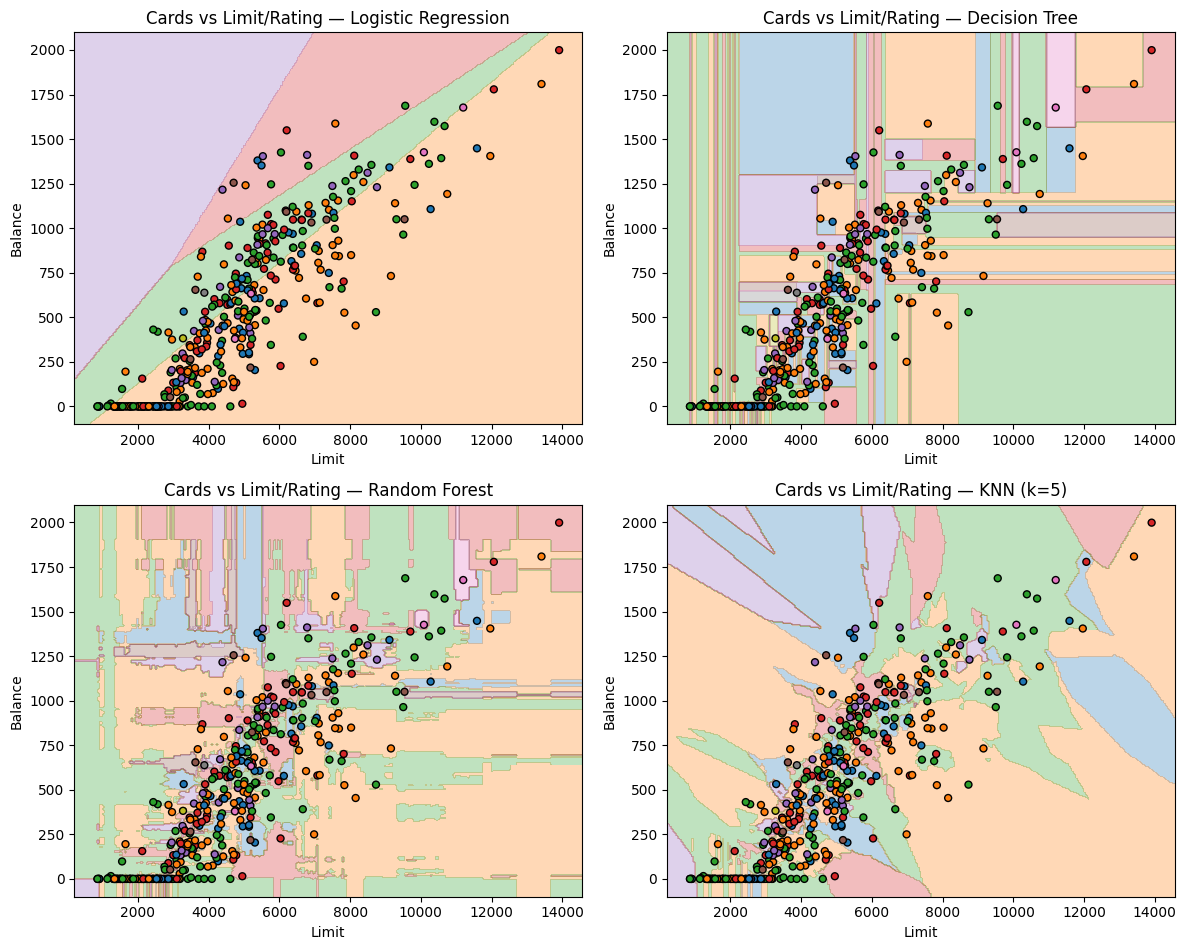

In [12]:
X2 = df[["Limit", "Balance"]]
y = df["Cards"]

le = LabelEncoder()
y_enc = le.fit_transform(y)

x0_min, x0_max = X2.iloc[:, 0].min(), X2.iloc[:, 0].max()
x1_min, x1_max = X2.iloc[:, 1].min(), X2.iloc[:, 1].max()
pad0 = 0.05 * ((x0_max - x0_min) or 1.0)
pad1 = 0.05 * (x1_max - x1_min) or 1.0
x_min, x_max = x0_min - pad0, x0_max + pad0
y_min, y_max = x1_min - pad1, x1_max + pad1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

n_classes = len(np.unique(y_enc))
cmap = ListedColormap(sns.color_palette("tab10", n_classes))

n_models = len(models)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
if n_rows == 1 and n_cols == 1:
    axes = np.array([[axes]])
elif n_rows == 1:
    axes = np.array([axes])

for ax, (name, model) in zip(axes.ravel(), models.items()):
    model.fit(X2, y)
    grid_points = pd.DataFrame(
        np.c_[xx.ravel(), yy.ravel()],
        columns=X2.columns
    )
    Z = model.predict(grid_points)
    Z_enc = le.transform(Z)
    Z_enc = Z_enc.reshape(xx.shape)

    ax.contourf(xx, yy, Z_enc, alpha=0.3, cmap=cmap, levels=np.arange(n_classes + 1) - 0.5)
    scatter = ax.scatter(X2.iloc[:, 0], X2.iloc[:, 1], c=y_enc, cmap=cmap, edgecolor="k", s=25)

    ax.set_title(f"Cards vs Limit/Rating — {name}")
    ax.set_xlabel(X2.columns[0])
    ax.set_ylabel(X2.columns[1])

fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()